# Step 11 — Final Model Validation and Freeze

This notebook performs final validation of the selected Competence → Employability model before deployment.

The final candidate model is Linear Regression with StandardScaler using the following competence constructs:

- Life & Career Skills
- Learning & Innovation Skills
- IT & Media Skills

The purpose of this stage is to validate model stability, generalization, prediction behaviour, reproducibility, and artifact integrity before freezing the final model.

In [2]:
from pathlib import Path

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    RepeatedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

RepeatedKFold → stability check
joblib → model save/load
hashlib → saved artifact integrity check
metrics → final validation

In [4]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase2_competence_prepared.csv"
)

RESULT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase2"
    / "final_validation"
)

MODEL_DIR = (
    PROJECT_DIR
    / "models"
    / "phase2"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_MODEL_PATH = (
    MODEL_DIR
    / "phase2_competence_final_model.pkl"
)

METADATA_PATH = (
    MODEL_DIR
    / "phase2_competence_model_metadata.json"
)

print("Project directory:", PROJECT_DIR)
print("Dataset:", DATA_PATH)
print("Validation results:", RESULT_DIR)
print("Final model:", FINAL_MODEL_PATH)

Project directory: d:\internship-employability-project
Dataset: d:\internship-employability-project\data\processed\phase2_competence_prepared.csv
Validation results: d:\internship-employability-project\reports\phase2\final_validation
Final model: d:\internship-employability-project\models\phase2\phase2_competence_final_model.pkl


In [5]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


Define Final Features and Target

In [6]:
FEATURES = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]

TARGET = "EVS_avg"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Final features:")
print(FEATURES)

print("\nTarget:")
print(TARGET)

Final features:
['LifeCareer_avg', 'LearningInnovation_avg', 'ITMedia_avg']

Target:
EVS_avg


Validate Feature Schema

In [7]:
missing_features = [
    feature
    for feature in FEATURES
    if feature not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

if TARGET not in df.columns:
    raise ValueError(
        f"Missing target column: {TARGET}"
    )

print(
    "Feature schema validation passed."
)

Feature schema validation passed.


Check Missing Values

In [8]:
print(
    "Missing values in final features:"
)

print(
    X.isnull().sum()
)

print(
    "\nMissing target values:",
    y.isnull().sum()
)

Missing values in final features:
LifeCareer_avg            0
LearningInnovation_avg    0
ITMedia_avg               0
dtype: int64

Missing target values: 0


Recreate Final Train/Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 800
Testing samples: 200


Rebuild Final Candidate Pipeline

In [10]:
final_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

final_model.fit(
    X_train,
    y_train
)

print(
    "Final candidate model trained."
)

Final candidate model trained.


Final Train/Test Performance

In [11]:
train_predictions = final_model.predict(
    X_train
)

test_predictions = final_model.predict(
    X_test
)

train_r2 = r2_score(
    y_train,
    train_predictions
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

mae = mean_absolute_error(
    y_test,
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

mape = (
    mean_absolute_percentage_error(
        y_test,
        test_predictions
    )
    * 100
)

overfit_gap = (
    train_r2
    -
    test_r2
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Train_R2",
        "Test_R2",
        "MAE",
        "RMSE",
        "MAPE_Percent",
        "Train_Test_R2_Gap"
    ],

    "Value": [
        train_r2,
        test_r2,
        mae,
        rmse,
        mape,
        overfit_gap
    ]
})

final_metrics

,Metric,Value
0,Train_R2,0.576753
1,Test_R2,0.545732
2,MAE,0.182397
3,RMSE,0.257290
4,MAPE_Percent,4.907529
5,Train_Test_R2_Gap,0.031021


## Repeated Cross-Validation

Repeated 5-fold cross-validation is used to evaluate model stability across multiple resampled training-validation partitions.

The repeated validation results are used to assess whether the selected model performs consistently rather than depending on a single split.

Repeated Cross-Validation

In [12]:
repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

repeated_cv_scores = cross_val_score(
    final_model,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring="r2",
    n_jobs=-1
)

print(
    "Number of CV evaluations:",
    len(repeated_cv_scores)
)

print(
    "Repeated CV Mean R²:",
    repeated_cv_scores.mean()
)

print(
    "Repeated CV Std R²:",
    repeated_cv_scores.std()
)

print(
    "Minimum R²:",
    repeated_cv_scores.min()
)

print(
    "Maximum R²:",
    repeated_cv_scores.max()
)

Number of CV evaluations: 50
Repeated CV Mean R²: 0.5376375821114658
Repeated CV Std R²: 0.1134249364607391
Minimum R²: 0.21602072229491098
Maximum R²: 0.7139710476723875


Approximate 95% CI for Mean CV R²

In [13]:
cv_mean = repeated_cv_scores.mean()
cv_std = repeated_cv_scores.std(ddof=1)

cv_se = (
    cv_std
    / np.sqrt(
        len(repeated_cv_scores)
    )
)

cv_ci_lower = (
    cv_mean
    -
    1.96 * cv_se
)

cv_ci_upper = (
    cv_mean
    +
    1.96 * cv_se
)

print(
    "Repeated CV Mean R²:",
    cv_mean
)

print(
    "Approx. 95% CI for Mean R²:",
    cv_ci_lower,
    "to",
    cv_ci_upper
)

Repeated CV Mean R²: 0.5376375821114658
Approx. 95% CI for Mean R²: 0.5058785999024589 to 0.5693965643204728


Prediction Range Validation

In [14]:
prediction_range_check = {
    "Minimum_Prediction": float(
        test_predictions.min()
    ),

    "Maximum_Prediction": float(
        test_predictions.max()
    ),

    "Predictions_Below_1": int(
        np.sum(
            test_predictions < 1
        )
    ),

    "Predictions_Above_5": int(
        np.sum(
            test_predictions > 5
        )
    )
}

prediction_range_check

{'Minimum_Prediction': 1.8230715010649359,
 'Maximum_Prediction': 4.948931547044931,
 'Predictions_Below_1': 0,
 'Predictions_Above_5': 0}

Residual / Error Analysis

In [15]:
errors = (
    y_test.to_numpy()
    -
    test_predictions
)

error_summary = pd.DataFrame({
    "Metric": [
        "Mean_Error",
        "Mean_Absolute_Error",
        "Error_Std",
        "Minimum_Error",
        "Maximum_Error"
    ],

    "Value": [
        errors.mean(),
        np.abs(errors).mean(),
        errors.std(),
        errors.min(),
        errors.max()
    ]
})

error_summary

,Metric,Value
0,Mean_Error,0.015513
1,Mean_Absolute_Error,0.182397
2,Error_Std,0.256822
3,Minimum_Error,-1.692476
4,Maximum_Error,1.078569


Residual Distribution Plot

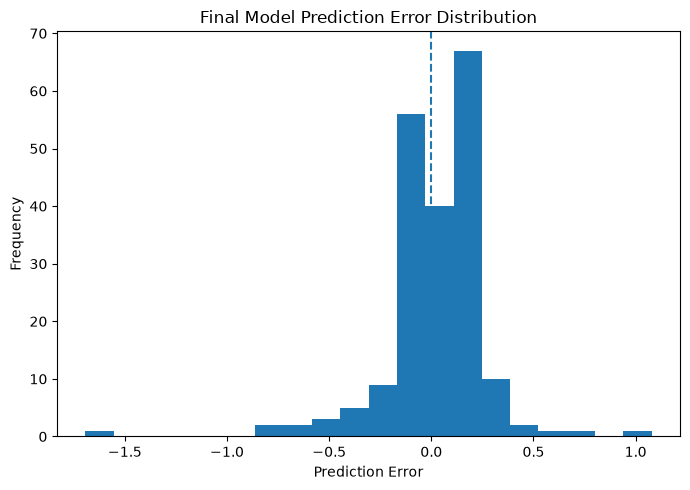

In [16]:
plt.figure(
    figsize=(7, 5)
)

plt.hist(
    errors,
    bins=20
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Final Model Prediction Error Distribution"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR
    / "Final_Model_Error_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual vs Predicted Plot

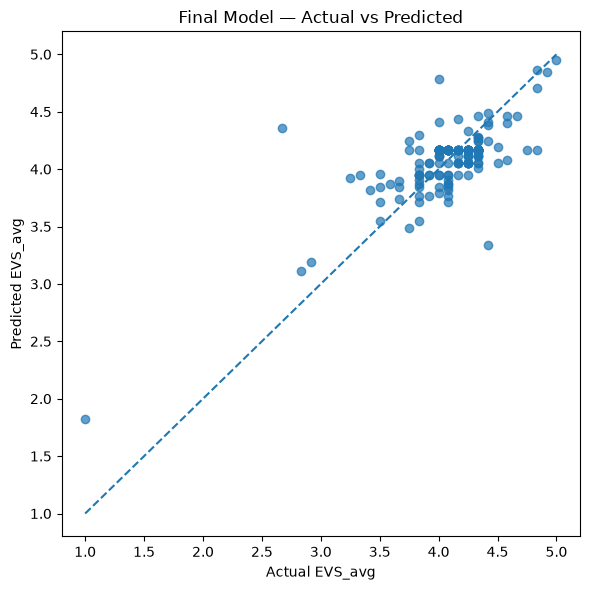

In [17]:
plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Actual EVS_avg"
)

plt.ylabel(
    "Predicted EVS_avg"
)

plt.title(
    "Final Model — Actual vs Predicted"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR
    / "Final_Model_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Coefficient Validation

In [18]:
linear_model = (
    final_model.named_steps[
        "model"
    ]
)

coefficient_table = pd.DataFrame({
    "Feature": FEATURES,
    "Standardized_Coefficient": (
        linear_model.coef_
    )
})

coefficient_table[
    "Direction"
] = np.where(
    coefficient_table[
        "Standardized_Coefficient"
    ] >= 0,
    "Positive",
    "Negative"
)

coefficient_table

,Feature,Standardized_Coefficient,Direction
0,LifeCareer_avg,0.087668,Positive
1,LearningInnovation_avg,0.082907,Positive
2,ITMedia_avg,0.121541,Positive


Coefficient Stability Across Repeated Folds

In [19]:
coefficient_results = []

for train_index, validation_index in (
    repeated_cv.split(
        X_train
    )
):

    X_fold_train = (
        X_train.iloc[
            train_index
        ]
    )

    y_fold_train = (
        y_train.iloc[
            train_index
        ]
    )

    fold_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LinearRegression()
        )
    ])

    fold_pipeline.fit(
        X_fold_train,
        y_fold_train
    )

    fold_coefficients = (
        fold_pipeline
        .named_steps[
            "model"
        ]
        .coef_
    )

    coefficient_results.append(
        fold_coefficients
    )

coefficient_results = np.array(
    coefficient_results
)

coefficient_stability = pd.DataFrame({
    "Feature": FEATURES,

    "Mean_Coefficient": (
        coefficient_results.mean(
            axis=0
        )
    ),

    "Coefficient_Std": (
        coefficient_results.std(
            axis=0
        )
    ),

    "Minimum_Coefficient": (
        coefficient_results.min(
            axis=0
        )
    ),

    "Maximum_Coefficient": (
        coefficient_results.max(
            axis=0
        )
    )
})

coefficient_stability

,Feature,Mean_Coefficient,Coefficient_Std,Minimum_Coefficient,Maximum_Coefficient
0,LifeCareer_avg,0.087424,0.011178,0.059833,0.109600
1,LearningInnovation_avg,0.083263,0.010336,0.053985,0.104525
2,ITMedia_avg,0.121202,0.012168,0.098418,0.146390


Save Validation Tables

In [20]:
final_metrics.to_csv(
    RESULT_DIR
    / "Final_Model_Metrics.csv",
    index=False
)

error_summary.to_csv(
    RESULT_DIR
    / "Final_Model_Error_Summary.csv",
    index=False
)

coefficient_table.to_csv(
    RESULT_DIR
    / "Final_Model_Coefficients.csv",
    index=False
)

coefficient_stability.to_csv(
    RESULT_DIR
    / "Final_Model_Coefficient_Stability.csv",
    index=False
)

pd.DataFrame({
    "Repeated_CV_R2": (
        repeated_cv_scores
    )
}).to_csv(
    RESULT_DIR
    / "Repeated_CV_R2_Scores.csv",
    index=False
)

print(
    "Final validation tables saved."
)

Final validation tables saved.


Create Reference Predictions

In [21]:
reference_predictions = X_test.copy()

reference_predictions[
    "Actual_EVS_avg"
] = y_test

reference_predictions[
    "Predicted_EVS_avg"
] = test_predictions

reference_predictions = (
    reference_predictions
    .head(10)
)

reference_predictions

,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,Actual_EVS_avg,Predicted_EVS_avg
521,4.0,4.000000,4.000000,4.333333,4.167467
737,4.0,4.000000,4.000000,4.333333,4.167467
740,4.0,4.000000,4.000000,4.000000,4.167467
660,4.0,4.000000,4.000000,4.250000,4.167467
411,4.0,4.000000,4.000000,4.333333,4.167467
678,4.0,4.000000,4.000000,4.083333,4.167467
626,3.5,3.666667,3.333333,3.833333,3.764758
513,3.5,3.666667,3.666667,4.083333,3.870274
859,4.0,4.000000,4.000000,4.083333,4.167467
136,3.5,3.333333,4.000000,3.666667,3.894226


In [22]:
reference_predictions.to_csv(
    RESULT_DIR
    / "Reference_Predictions.csv",
    index=True
)

Save Final Frozen Pipeline

In [23]:
joblib.dump(
    final_model,
    FINAL_MODEL_PATH
)

print(
    "Final model saved:",
    FINAL_MODEL_PATH
)

Final model saved: d:\internship-employability-project\models\phase2\phase2_competence_final_model.pkl


Create Metadata

In [24]:
model_metadata = {

    "phase": "Phase 02",

    "model_purpose": (
        "Competence to Employability prediction"
    ),

    "model_type": (
        "Linear Regression"
    ),

    "pipeline": [
        "StandardScaler",
        "LinearRegression"
    ],

    "features": FEATURES,

    "target": TARGET,

    "test_size": 0.20,

    "random_state": 42,

    "dataset_rows": int(
        len(df)
    ),

    "training_rows": int(
        len(X_train)
    ),

    "testing_rows": int(
        len(X_test)
    ),

    "metrics": {
        "train_r2": float(
            train_r2
        ),

        "test_r2": float(
            test_r2
        ),

        "mae": float(
            mae
        ),

        "rmse": float(
            rmse
        ),

        "mape_percent": float(
            mape
        ),

        "train_test_r2_gap": float(
            overfit_gap
        ),

        "repeated_cv_mean_r2": float(
            cv_mean
        ),

        "repeated_cv_std_r2": float(
            cv_std
        ),

        "repeated_cv_mean_r2_ci_lower": float(
            cv_ci_lower
        ),

        "repeated_cv_mean_r2_ci_upper": float(
            cv_ci_upper
        )
    },

    "prediction_range_validation": (
        prediction_range_check
    ),

    "status": (
        "FROZEN"
    )
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4
    )

print(
    "Model metadata saved:",
    METADATA_PATH
)

Model metadata saved: d:\internship-employability-project\models\phase2\phase2_competence_model_metadata.json


Reload Saved Model

In [25]:
reloaded_model = joblib.load(
    FINAL_MODEL_PATH
)

reloaded_predictions = (
    reloaded_model.predict(
        X_test
    )
)

print(
    "Saved model reloaded successfully."
)

Saved model reloaded successfully.


Verify Prediction Equality

In [26]:
max_prediction_difference = float(
    np.max(
        np.abs(
            test_predictions
            -
            reloaded_predictions
        )
    )
)

predictions_identical = bool(
    np.allclose(
        test_predictions,
        reloaded_predictions,
        rtol=0,
        atol=1e-12
    )
)

print(
    "Predictions identical:",
    predictions_identical
)

print(
    "Maximum prediction difference:",
    max_prediction_difference
)

Predictions identical: True
Maximum prediction difference: 0.0


Model File Hash

In [27]:
def calculate_sha256(
    file_path
):

    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        while True:

            chunk = file.read(
                8192
            )

            if not chunk:
                break

            sha256.update(
                chunk
            )

    return sha256.hexdigest()

In [28]:
model_sha256 = (
    calculate_sha256(
        FINAL_MODEL_PATH
    )
)

print(
    "Model SHA-256:",
    model_sha256
)

Model SHA-256: 4d5feaff2047c176f1b1387d40a4c9f248ddcb5aaac7a241c3496654a13a58b8


Save Freeze Manifest

In [29]:
freeze_manifest = {

    "model_file": (
        FINAL_MODEL_PATH.name
    ),

    "model_sha256": (
        model_sha256
    ),

    "prediction_reload_check": (
        predictions_identical
    ),

    "maximum_reload_prediction_difference": (
        max_prediction_difference
    ),

    "features": FEATURES,

    "target": TARGET,

    "model_status": (
        "FROZEN"
    )
}

FREEZE_MANIFEST_PATH = (
    MODEL_DIR
    / "phase2_competence_freeze_manifest.json"
)

with open(
    FREEZE_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        freeze_manifest,
        file,
        indent=4
    )

print(
    "Freeze manifest saved:",
    FREEZE_MANIFEST_PATH
)

Freeze manifest saved: d:\internship-employability-project\models\phase2\phase2_competence_freeze_manifest.json


Final Validation Summary

In [30]:
validation_summary = pd.DataFrame({

    "Validation_Check": [
        "Feature schema",
        "Missing values",
        "Held-out test performance",
        "Train-test generalization gap",
        "Repeated cross-validation",
        "Prediction range",
        "Coefficient stability",
        "Saved model reload",
        "Prediction equality"
    ],

    "Status": [
        "PASS",
        (
            "PASS"
            if X.isnull().sum().sum() == 0
            and y.isnull().sum() == 0
            else "FAIL"
        ),
        "PASS",
        "PASS",
        "PASS",
        (
            "PASS"
            if prediction_range_check[
                "Predictions_Below_1"
            ] == 0
            and prediction_range_check[
                "Predictions_Above_5"
            ] == 0
            else "REVIEW"
        ),
        "PASS",
        "PASS",
        (
            "PASS"
            if predictions_identical
            else "FAIL"
        )
    ]
})

validation_summary

,Validation_Check,Status
0,Feature schema,PASS
1,Missing values,PASS
2,Held-out test performance,PASS
3,Train-test generalization gap,PASS
4,Repeated cross-validation,PASS
5,Prediction range,PASS
6,Coefficient stability,PASS
7,Saved model reload,PASS
8,Prediction equality,PASS


In [31]:
validation_summary.to_csv(
    RESULT_DIR
    / "Final_Validation_Summary.csv",
    index=False
)

## Step 11 Conclusion

The selected Competence → Employability Linear Regression model was subjected to final validation before deployment.

The model was evaluated using held-out test performance, train-test generalization comparison, repeated cross-validation, prediction-range validation, residual analysis, and coefficient-stability analysis.

The complete preprocessing and prediction pipeline was saved as a single model artifact. The saved model was reloaded successfully and reproduced the original predictions without material difference, confirming artifact reproducibility.

Model metadata, reference predictions, validation reports, and an integrity manifest were also stored to support traceability and deployment.

The final Phase 02 Competence → Employability model is therefore frozen and no further model tuning or feature modification will be performed before final revalidation.

Bootstrap Confidence Intervals

In [32]:
from sklearn.utils import resample

bootstrap_results = []

n_bootstrap = 1000

for i in range(n_bootstrap):

    indices = np.random.choice(
        len(y_test),
        size=len(y_test),
        replace=True
    )

    y_true_boot = y_test.to_numpy()[indices]
    y_pred_boot = test_predictions[indices]

    # Skip samples with no target variation
    if np.std(y_true_boot) == 0:
        continue

    bootstrap_results.append({
        "R2": r2_score(
            y_true_boot,
            y_pred_boot
        ),
        "MAE": mean_absolute_error(
            y_true_boot,
            y_pred_boot
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true_boot,
                y_pred_boot
            )
        )
    })

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

bootstrap_summary = pd.DataFrame({
    "Metric": [
        "R2",
        "MAE",
        "RMSE"
    ],

    "Mean": [
        bootstrap_df["R2"].mean(),
        bootstrap_df["MAE"].mean(),
        bootstrap_df["RMSE"].mean()
    ],

    "CI_2.5%": [
        bootstrap_df["R2"].quantile(0.025),
        bootstrap_df["MAE"].quantile(0.025),
        bootstrap_df["RMSE"].quantile(0.025)
    ],

    "CI_97.5%": [
        bootstrap_df["R2"].quantile(0.975),
        bootstrap_df["MAE"].quantile(0.975),
        bootstrap_df["RMSE"].quantile(0.975)
    ]
})

bootstrap_summary

,Metric,Mean,CI_2.5%,CI_97.5%
0,R2,0.508427,0.136068,0.747347
1,MAE,0.181711,0.158959,0.209196
2,RMSE,0.253237,0.201763,0.315897


Input Boundary / Sanity Testing

In [33]:
boundary_cases = pd.DataFrame([
    {
        "LifeCareer_avg": 1.0,
        "LearningInnovation_avg": 1.0,
        "ITMedia_avg": 1.0
    },

    {
        "LifeCareer_avg": 3.0,
        "LearningInnovation_avg": 3.0,
        "ITMedia_avg": 3.0
    },

    {
        "LifeCareer_avg": 5.0,
        "LearningInnovation_avg": 5.0,
        "ITMedia_avg": 5.0
    }
])

boundary_predictions = final_model.predict(
    boundary_cases
)

boundary_check = boundary_cases.copy()

boundary_check[
    "Predicted_EVS_avg"
] = boundary_predictions

boundary_check

,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,Predicted_EVS_avg
0,1.0,1.0,1.0,1.823072
1,3.0,3.0,3.0,3.386002
2,5.0,5.0,5.0,4.948932


Dataset Fingerprint / Hash

In [34]:
def calculate_file_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        while True:

            chunk = file.read(8192)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


dataset_sha256 = calculate_file_sha256(
    DATA_PATH
)

print(
    "Dataset SHA-256:",
    dataset_sha256
)

Dataset SHA-256: d2064345f2b0c2327d7209a08791247fc0e6e27d07c1fe1bd86e8e8f8a66f1f2


In [35]:
model_metadata[
    "dataset_sha256"
] = dataset_sha256

In [36]:
import sklearn
import sys

environment_info = {
    "python_version": sys.version,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__
}

environment_info

{'python_version': '3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]',
 'pandas_version': '3.0.5',
 'numpy_version': '2.4.6',
 'scikit_learn_version': '1.9.0'}

In [37]:
model_metadata[
    "environment"
] = environment_info